# 📈 S23 · Laboratorio de Streamlit: Mi Observatorio Financiero
**Lenguajes de Programación · Ingeniería Financiera · Google Colab · Taller 6**

> **Reto:** convertir un análisis en Python en una aplicación web que permita elegir activos, comparar su comportamiento y explicar los resultados.

**Al finalizar podrás:** crear una interfaz, distribuir contenido con `st.columns`, organizar pestañas con `st.tabs`, agregar imágenes, capturar decisiones del usuario, representar series financieras y guardar tu aplicación en GitHub.

**Cómo trabajar:** ejecuta las celdas en orden. Las celdas `%%writefile app.py` **reemplazan** el archivo por una versión nueva; antes de avanzar se guarda una copia. El servidor se inicia una sola vez y detecta cambios en `app.py`.

**Importante:** Colab ejecuta Python en un equipo remoto. El archivo `app.py` se modifica en el entorno de Colab; la interfaz se visualiza en otra pestaña del navegador. No se requiere instalar Python en tu computador.

## 01 · Preparar el entorno

**¿Qué es Streamlit?** Una biblioteca de Python que convierte instrucciones como `st.title()` o `st.selectbox()` en componentes de una página web.

| En un notebook | En Streamlit |
|---|---|
| `print(resultado)` muestra texto en una celda | `st.metric()` muestra un indicador |
| `df.plot()` crea un gráfico en el notebook | `st.line_chart()` lo presenta en la aplicación |
| Se cambian variables editando código | El usuario cambia parámetros con controles |

Primero instalamos las bibliotecas. **No ejecutes `streamlit run` directamente con `!` sin segundo plano**, porque la celda quedaría ocupada.

In [ ]:
%pip -q install "streamlit>=1.38,<2" "yfinance>=0.2.50,<2" "plotly>=5.24,<7" "pandas>=2.1,<3" "numpy>=1.26,<3" pillow requests

In [ ]:
import sys, streamlit, pandas, numpy, plotly, yfinance
print("Python:", sys.version.split()[0])
print("Streamlit:", streamlit.__version__)
print("Pandas:", pandas.__version__)
print("Plotly:", plotly.__version__)
print("yfinance:", yfinance.__version__)

Python: 3.13.18
Streamlit: 1.66.1
Pandas: 2.2.3
Plotly: 5.24.1
yfinance: 0.2.66


## 02 · Primera aplicación: título y mensaje

`st.title()` crea un título grande; `st.write()` presenta contenido; `st.info()` destaca un mensaje. Observa cómo cada instrucción de Python se convierte en una parte visible de la página.

**Actividad:** cambia el título por el nombre de tu proyecto y agrega una frase que explique qué problema financiero quieres analizar.

In [ ]:
%%writefile app.py
import streamlit as st

st.set_page_config(page_title="Mi Observatorio Financiero", page_icon="📈", layout="wide")
st.title("📈 Mi Observatorio Financiero")
st.write("Una aplicación creada con Python y Streamlit.")
st.info("Hoy aprenderemos a construir esta interfaz paso a paso.")


Writing app.py


### Guardar una versión recuperable

Cada etapa conserva una copia. Si algo falla, podrás recuperar una versión funcional sin empezar de nuevo.

In [ ]:
from pathlib import Path
from datetime import datetime
Path("versiones").mkdir(exist_ok=True)
Path("versiones/01_primera_app.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 01 guardada")

Versión 01 guardada


## 03 · Iniciar Streamlit y comprobar que responde

El servidor se ejecutará **en segundo plano** y la celda terminará. Después verificaremos la dirección local `http://127.0.0.1:8501/_stcore/health`.

**No avances al túnel si la comprobación no muestra `200 / ok`.**

In [ ]:
import subprocess, time, requests
from pathlib import Path

# Evita dejar varios servidores compitiendo por el puerto 8501.
subprocess.run(["pkill", "-f", "[s]treamlit run app.py"], check=False)
log_streamlit = open("/tmp/s23_streamlit.log", "w")
servidor = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.headless=true", "--server.fileWatcherType=poll"],
    stdout=log_streamlit, stderr=subprocess.STDOUT, start_new_session=True
)

for intento in range(20):
    try:
        respuesta = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=2)
        if respuesta.status_code == 200:
            print("✅ Streamlit funcionando:", respuesta.status_code, respuesta.text)
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    print("❌ No responde Streamlit. Últimos mensajes:")
    print(Path("/tmp/s23_streamlit.log").read_text(errors="replace")[-3000:])

✅ Streamlit funcionando: 200 ok


## 04 · Abrir la aplicación en el navegador

En sesiones anteriores, **LocalTunnel produjo errores 502** y no cargó los módulos JavaScript de `multiselect` y `dataframe`. Por eso aquí usamos **Cloudflare Quick Tunnel**, también temporal.

**Limitación:** no podemos garantizar la disponibilidad de un túnel externo en todas las sesiones de Colab. Si falla, conserva el código y utiliza el despliegue alternativo en Streamlit Community Cloud al final del laboratorio.

In [ ]:
import platform, urllib.request, os
from pathlib import Path
arquitectura = platform.machine().lower()
archivo = {"x86_64":"cloudflared-linux-amd64", "aarch64":"cloudflared-linux-arm64"}.get(arquitectura)
if not archivo:
    raise RuntimeError(f"Arquitectura no contemplada: {arquitectura}")
url = f"https://github.com/cloudflare/cloudflared/releases/latest/download/{archivo}"
if not Path("/tmp/cloudflared").exists():
    urllib.request.urlretrieve(url, "/tmp/cloudflared")
os.chmod("/tmp/cloudflared", 0o755)
print("Cloudflared preparado para", arquitectura)

Cloudflared preparado para x86_64


In [ ]:
import re, subprocess, time
from pathlib import Path
subprocess.run(["pkill", "-f", "[c]loudflared tunnel --url"], check=False)
registro = open("/tmp/s23_cloudflare.log", "w")
tunel = subprocess.Popen(
    ["/tmp/cloudflared", "tunnel", "--url", "http://127.0.0.1:8501", "--no-autoupdate"],
    stdout=registro, stderr=subprocess.STDOUT, start_new_session=True
)
url_publica = None
for intento in range(25):
    time.sleep(1)
    texto = Path("/tmp/s23_cloudflare.log").read_text(errors="replace")
    encontrado = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", texto)
    if encontrado:
        url_publica = encontrado.group(0)
        break
if url_publica:
    print("🌐 ABRE TU APLICACIÓN EN UNA PESTAÑA NUEVA:", url_publica)
else:
    print("No se obtuvo URL. Diagnóstico:")
    print(texto[-2500:])

🌐 ABRE TU APLICACIÓN EN UNA PESTAÑA NUEVA: https://sandy-newspaper-rom-officials.trycloudflare.com


**Comprobación visual:** al abrir el enlace debe verse el título **Mi Observatorio Financiero**. Si aparece `502 Bad Gateway`, ejecuta el diagnóstico siguiente; no modifiques el código de la aplicación todavía.

In [ ]:
from pathlib import Path
import requests
try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Servidor local:", r.status_code, r.text)
except Exception as e:
    print("Servidor local sin respuesta:", e)
print("\nRegistro Streamlit:\n", Path("/tmp/s23_streamlit.log").read_text(errors="replace")[-900:])
print("\nRegistro Cloudflare:\n", Path("/tmp/s23_cloudflare.log").read_text(errors="replace")[-900:])

Servidor local: 200 ok

Registro Streamlit:
 

2026-10-27 23:26:11.974 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.243.230.165:8501



Registro Cloudflare:
 t=region1.v2.argotunnel.com
2026-10-27T23:27:56Z INF precheck component="UDP Connectivity" details="QUIC connection successful" run_id=383ca944-5fe5-4e71-b32d-259ec0b11bf0 status=pass target=region2.v2.argotunnel.com
2026-10-27T23:27:56Z INF precheck component="TCP Connectivity" details="HTTP/2 connection successful" run_id=383ca944-5fe5-4e71-b32d-259ec0b11bf0 status=pass target=region1.v2.argotunnel.com
2026-10-27T23:27:56Z INF precheck component="TCP Connectivity" details="HTTP/2 connection successful" run_id=383ca944-5fe5-4e71-b32d-259ec0b11bf0 status=pass target=region2.v2.argotunnel.com
2026-10-27T23:27:56Z INF precheck component="Cloudflare API" details="API is reachable" run_

## 05 · Diseñar el layout: barra lateral, columnas y pestañas

**Layout** significa la distribución de los componentes en pantalla.

- `st.sidebar`: panel lateral para configurar el análisis.
- `st.columns(2)`: divide una sección en dos columnas.
- `st.tabs([...])`: organiza contenidos en pestañas.
- `with`: indica en qué columna o pestaña aparecerá cada elemento.

**Antes de ejecutar:** predice dónde aparecerá cada texto. Después abre el navegador y verifica.

In [ ]:
%%writefile app.py
import streamlit as st

st.set_page_config(page_title="Mi Observatorio Financiero", page_icon="📈", layout="wide")
st.title("📈 Mi Observatorio Financiero")
st.caption("Laboratorio de aplicaciones financieras · ITM")

st.sidebar.header("⚙️ Configuración")
st.sidebar.write("Aquí elegiremos activos y períodos.")

col1, col2 = st.columns(2)
with col1:
    st.metric("Capital de ejemplo", "$10,000")
with col2:
    st.metric("Activos de ejemplo", "3")

pestana1, pestana2, pestana3 = st.tabs(["📈 Portafolio", "📊 Estadística", "ℹ️ Proyecto"])
with pestana1:
    st.subheader("Análisis de portafolio")
    st.write("Aquí mostraremos precios y rendimientos.")
with pestana2:
    st.subheader("Estadística descriptiva")
    st.write("Aquí mostraremos media y desviación estándar.")
with pestana3:
    st.subheader("Acerca del proyecto")
    st.write("Creado con Python y Streamlit.")


Overwriting app.py


In [ ]:
from pathlib import Path
Path("versiones/02_layout.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 02 guardada. Vuelve a la pestaña de Streamlit y pulsa Rerun si es necesario.")

Versión 02 guardada. Vuelve a la pestaña de Streamlit y pulsa Rerun si es necesario.


### ✍️ Practica con el layout

1. Cambia el nombre de la pestaña **Proyecto** por **Acerca de mí**.
2. Agrega una cuarta pestaña llamada **Riesgo**.
3. Usa `st.columns(3)` para mostrar tres indicadores.

**Cómo modificar `app.py`:** en Colab abre el icono de **Archivos** (panel izquierdo), haz doble clic en `app.py`, cambia el texto y guarda con `Ctrl+S` / `Cmd+S`. El servidor normalmente detecta el cambio y ofrece **Rerun**. **No vuelvas a ejecutar una celda `%%writefile` anterior**, porque sobrescribirá tus cambios.

## 06 · Agregar imágenes y componentes interactivos

`st.image()` permite mostrar una imagen. En este ejemplo **crearemos una imagen con Pillow**, sin depender de páginas externas. Después usaremos `st.multiselect`, `st.selectbox`, `st.slider` y `st.number_input`.

**Concepto clave:** el valor que devuelve un widget es una variable de Python; al cambiarlo, Streamlit vuelve a ejecutar el script con los valores seleccionados.

Imagen creada: assets/banner_financiero.png


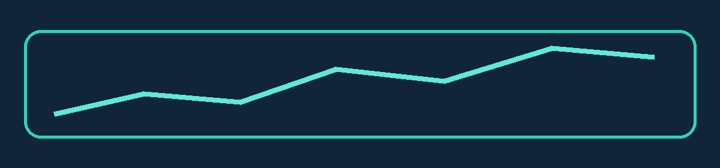

In [ ]:
from PIL import Image, ImageDraw
from pathlib import Path
Path("assets").mkdir(exist_ok=True)
imagen = Image.new("RGB", (1200, 280), "#10243a")
d = ImageDraw.Draw(imagen)
d.rounded_rectangle((40, 50, 1160, 230), radius=28, outline="#2dd4bf", width=5)
d.line([(90, 190), (240, 156), (400, 170), (560, 115), (740, 135), (920, 80), (1090, 95)], fill="#5eead4", width=9, joint="curve")
imagen.save("assets/banner_financiero.png")
print("Imagen creada: assets/banner_financiero.png")
display(imagen.resize((720,168)))

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np

st.set_page_config(page_title="Mi Observatorio Financiero", page_icon="📈", layout="wide")
st.image("assets/banner_financiero.png", use_container_width=True)
st.title("Mi Observatorio Financiero")
st.caption("Aprendemos a construir interfaces con Python")

st.sidebar.header("⚙️ Configuración")
activos = st.sidebar.multiselect("Elige activos", ["AAPL", "MSFT", "NVDA", "JPM"], default=["AAPL", "MSFT"])
periodo = st.sidebar.selectbox("Período", ["3 meses", "6 meses", "1 año"], index=2)
capital = st.sidebar.number_input("Capital inicial (USD)", min_value=100, value=10000, step=500)
ventana = st.sidebar.slider("Ventana de media móvil", 5, 30, 10)

st.write("**Activos elegidos:**", ", ".join(activos) if activos else "Ninguno")
st.write("**Período:**", periodo)

# Datos simulados y reproducibles: funcionan sin internet.
rng = np.random.default_rng(23)
fechas = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=90)
precios = pd.DataFrame(index=fechas)
for ticker in activos:
    variaciones = rng.normal(0.0005, 0.015, len(fechas))
    precios[ticker] = 100 * np.cumprod(1 + variaciones)

p1, p2, p3 = st.tabs(["📈 Portafolio", "📊 Estadística", "ℹ️ Proyecto"])
with p1:
    a, b = st.columns(2)
    with a:
        st.metric("Capital configurado", f"USD {capital:,.0f}")
    with b:
        st.metric("Número de activos", len(activos))
    if activos:
        st.line_chart(precios)
        st.caption("Gráfico construido con datos simulados, no cotizaciones reales.")
        st.line_chart(precios.rolling(ventana).mean())
    else:
        st.info("Selecciona al menos un activo.")
with p2:
    if activos:
        rendimientos = precios.pct_change().dropna()
        st.dataframe(rendimientos.describe(), use_container_width=True)
    else:
        st.info("No hay activos seleccionados.")
with p3:
    st.write("Imagen creada con Pillow; gráficos y controles creados con Streamlit.")


Overwriting app.py


In [ ]:
from pathlib import Path
Path("versiones/03_widgets_imagen.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión 03 guardada")

Versión 03 guardada


### ✍️ Prueba los controles

- Quita un ticker y observa el gráfico.
- Cambia la media móvil de 10 a 20 sesiones. ¿Por qué se suaviza la curva?
- Cambia el capital inicial. ¿Qué indicador cambia y cuál permanece igual?
- Modifica el color del banner en la celda de Pillow y vuelve a crear la imagen.

**Pregunta de análisis:** ¿por qué conviene distinguir entre datos simulados y precios reales?

## 07 · Conectar Yahoo Finance y calcular indicadores

Ahora utilizaremos precios históricos de mercado. La app sigue funcionando con datos de ejemplo si Yahoo Finance no responde, **pero muestra claramente cuándo utiliza datos simulados**.

Fórmulas esenciales:

- **Rendimiento diario:** \(r_t = P_t/P_{t-1}-1\).
- **Rendimiento acumulado:** \(R=\prod_t(1+r_t)-1\).
- **Volatilidad anualizada:** \(\sigma_a=\sigma_d\sqrt{252}\).
- **Correlación:** relación lineal entre rendimientos de dos activos, entre −1 y +1.

Para el portafolio de pesos iguales, el rendimiento diario es la media de los rendimientos diarios de los activos. Es un supuesto de **rebalanceo diario** y no incorpora comisiones.

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import yfinance as yf
import plotly.express as px

st.set_page_config(page_title="Observatorio Financiero · ITM", page_icon="📈", layout="wide")
st.markdown("""<style>
[data-testid="stApp"]{background:linear-gradient(145deg,#0b1425,#101f33);color:#edf4ff}
[data-testid="stSidebar"]{background:#0d1c30}
[data-testid="stMetric"]{background:#172b43;padding:15px;border-radius:14px;border:1px solid #29415b}
h1,h2,h3{letter-spacing:-.03em}
</style>""", unsafe_allow_html=True)
st.image("assets/banner_financiero.png", use_container_width=True)
st.title("FinanceLab · Mi Observatorio Financiero")
st.caption("ITM · Python · Streamlit · Yahoo Finance")

UNIVERSO = ["AAPL", "MSFT", "NVDA", "JPM", "GOOGL", "SPY", "GLD"]
st.sidebar.header("⚙️ Configura tu análisis")
tickers = st.sidebar.multiselect("Tickers", UNIVERSO, default=["AAPL", "MSFT", "JPM"], max_selections=5)
periodo = st.sidebar.selectbox("Período histórico", ["3mo", "6mo", "1y", "2y"], index=2,
    format_func=lambda x: {"3mo":"3 meses", "6mo":"6 meses", "1y":"1 año", "2y":"2 años"}[x])
capital = st.sidebar.number_input("Capital inicial (USD)", min_value=100.0, value=10000.0, step=500.0)
fuente = st.sidebar.radio("Fuente de datos", ["Yahoo Finance", "Simulados (práctica)"], index=0)

@st.cache_data(ttl=1800, show_spinner=False)
def descargar_precios(simbolos, periodo):
    datos = yf.download(list(simbolos), period=periodo, auto_adjust=True, progress=False, threads=False)
    if datos.empty:
        raise ValueError("Yahoo Finance no devolvió datos")
    if isinstance(datos.columns, pd.MultiIndex):
        cierre = datos["Close"]
    else:
        cierre = datos[["Close"]].rename(columns={"Close": simbolos[0]})
    if isinstance(cierre, pd.Series):
        cierre = cierre.to_frame(name=simbolos[0])
    cierre = cierre.reindex(columns=list(simbolos))
    return cierre.sort_index().ffill().dropna()

def simular_precios(simbolos):
    rng = np.random.default_rng(23)
    fechas = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=180)
    return pd.DataFrame({t:100*np.cumprod(1+rng.normal(.0004,.014,len(fechas))) for t in simbolos}, index=fechas)

if not tickers:
    st.info("Selecciona al menos un ticker en la barra lateral.")
    st.stop()

simulados = fuente == "Simulados (práctica)"
if simulados:
    precios = simular_precios(tickers)
else:
    try:
        with st.spinner("Consultando Yahoo Finance..."):
            precios = descargar_precios(tuple(tickers), periodo)
        if precios.empty or len(precios) < 30:
            raise ValueError("No hay suficientes precios comunes")
    except Exception as error:
        st.warning("Yahoo Finance no está disponible. Se mostrarán DATOS SIMULADOS para continuar la práctica.")
        st.caption(f"Detalle técnico: {error}")
        precios = simular_precios(tickers)
        simulados = True

if simulados:
    st.error("MODO DEMOSTRACIÓN: los resultados NO corresponden a cotizaciones reales.")
else:
    st.success("Datos históricos descargados de Yahoo Finance")

rendimientos = precios.pct_change().dropna()
cartera = rendimientos.mean(axis=1)  # Pesos iguales, rebalanceo diario.
acumulado = (1 + cartera).cumprod()
rendimiento_total = acumulado.iloc[-1] - 1
volatilidad = cartera.std(ddof=1) * np.sqrt(252)
valor_inversion = capital * acumulado

c1, c2, c3 = st.columns(3)
c1.metric("Rendimiento acumulado", f"{rendimiento_total:+.2%}")
c2.metric("Volatilidad anualizada", f"{volatilidad:.2%}")
c3.metric("Valor final teórico", f"USD {valor_inversion.iloc[-1]:,.2f}")
st.caption("Portafolio con pesos iguales y rebalanceo diario; sin costos, impuestos ni dividendos adicionales.")

p1, p2, p3 = st.tabs(["📈 Portafolio", "📊 Estadística", "ℹ️ Proyecto"])
with p1:
    st.subheader("Comparación de activos · base 100")
    base_100 = precios.div(precios.iloc[0]) * 100
    st.line_chart(base_100)
    izquierda, derecha = st.columns(2)
    with izquierda:
        st.subheader("Valor de la inversión")
        st.line_chart(valor_inversion.rename("USD"))
    with derecha:
        st.subheader("Rendimiento diario de la cartera")
        st.bar_chart(cartera.mul(100).rename("%"))
    st.info("Interpretación: la escala base 100 permite comparar trayectorias aunque los activos tengan precios diferentes.")
with p2:
    st.subheader("Estadística descriptiva de rendimientos")
    resumen = pd.DataFrame({"Media diaria (%)":rendimientos.mean()*100,
                            "Mediana diaria (%)":rendimientos.median()*100,
                            "Desviación diaria (%)":rendimientos.std()*100,
                            "Mínimo diario (%)":rendimientos.min()*100,
                            "Máximo diario (%)":rendimientos.max()*100})
    st.dataframe(resumen.round(3), use_container_width=True)
    a, b = st.columns(2)
    with a:
        fig = px.histogram(x=cartera*100, nbins=30, title="Distribución de rendimientos diarios",
                           labels={"x":"Rendimiento (%)", "y":"Frecuencia"})
        st.plotly_chart(fig, use_container_width=True)
    with b:
        fig = px.imshow(rendimientos.corr(), text_auto=".2f", zmin=-1, zmax=1,
                        color_continuous_scale="RdBu_r", title="Correlaciones")
        st.plotly_chart(fig, use_container_width=True)
    st.info("Interpretación: una correlación alta no implica causalidad. La volatilidad mide dispersión de rendimientos.")
with p3:
    st.subheader("Cómo se construyó")
    st.write("**Layout:** sidebar, columns, tabs. **Widgets:** multiselect, selectbox, number_input.")
    st.write("**Datos:** yfinance, pandas. **Gráficos:** Streamlit y Plotly.")
    st.write("**Fórmulas:** rendimiento diario, rendimiento acumulado, desviación estándar anualizada.")

with st.expander("🔎 Ver datos y descargar CSV"):
    st.dataframe(precios.tail(30), use_container_width=True)
    st.download_button("Descargar precios CSV", precios.to_csv().encode("utf-8"), "precios_financelab.csv", "text/csv")
st.caption("Uso académico. Los resultados históricos no garantizan rentabilidades futuras.")


Overwriting app.py


In [ ]:
from pathlib import Path
Path("versiones/04_financelab_final.py").write_text(Path("app.py").read_text(encoding="utf-8"), encoding="utf-8")
print("Versión final guardada. Comprueba el navegador y modifica los tickers.")

Versión final guardada. Comprueba el navegador y modifica los tickers.


### Actividad de interpretación

1. Selecciona **AAPL, MSFT y JPM** durante **1 año**. ¿Cuál muestra mayor crecimiento en el gráfico base 100?
2. ¿Qué representa la **volatilidad anualizada**? ¿Un valor mayor significa necesariamente mayor rentabilidad?
3. Cambia a **SPY y GLD**. ¿Qué indica su correlación histórica? ¿Por qué podría cambiar en otro período?
4. Cambia de **Yahoo Finance** a **Simulados**. Explica por qué no debemos presentar datos simulados como datos de mercado.
5. Agrega una pestaña **Riesgo** y muestra una curva de drawdown utilizando:

```python
maximos = acumulado.cummax()
drawdown = acumulado / maximos - 1
st.line_chart(drawdown)
```

**Entrega:** captura de la interfaz funcionando y una interpretación escrita de al menos dos indicadores.

## 08 · Personalizar y entregar el proyecto

**Personalización mínima:** cambia el nombre del proyecto, ajusta colores, añade una pestaña, modifica los tickers y escribe una interpretación propia de los gráficos.

**Editar sin reiniciar el entorno:** abre `app.py` en el panel **Archivos** de Colab, guarda el cambio y pulsa **Rerun** en la página de Streamlit cuando aparezca. Si modificas una celda `%%writefile`, recuerda que al ejecutarla se reemplaza el archivo completo.

**Recuperar una versión anterior:** usa la siguiente celda cambiando el nombre de la versión. Atención: reemplaza el contenido actual de `app.py`.

In [ ]:
from pathlib import Path
print("Versiones disponibles:")
for ruta in sorted(Path("versiones").glob("*.py")):
    print(" -", ruta)
# Para recuperar una versión, descomenta y adapta estas dos líneas:
# version = Path("versiones/03_widgets_imagen.py")
# Path("app.py").write_text(version.read_text(encoding="utf-8"), encoding="utf-8")

Versiones disponibles:
 - versiones/01_primera_app.py
 - versiones/02_layout.py
 - versiones/03_widgets_imagen.py
 - versiones/04_financelab_final.py


### Archivos para GitHub

Se prepararán los archivos necesarios para publicar el proyecto: `app.py`, `requirements.txt`, `assets/banner_financiero.png` y `README.md`. **La carpeta `versiones/` es solo un respaldo de trabajo y no es obligatoria para entregar.**

In [ ]:
from pathlib import Path
Path("requirements.txt").write_text("streamlit>=1.38,<2\npandas>=2.1,<3\nnumpy>=1.26,<3\nyfinance>=0.2.50,<2\nplotly>=5.24,<7\npillow>=10,<13\n", encoding="utf-8")
Path("README.md").write_text("""# Mi Observatorio Financiero

Aplicación educativa construida con Python y Streamlit en la S23.

## Ejecución

```bash
pip install -r requirements.txt
streamlit run app.py
```

## Funcionalidades
Selección de tickers, comparación de precios, rendimiento, volatilidad y estadística descriptiva.

## Fuente
Yahoo Finance mediante yfinance; si falla, la app informa que utiliza datos simulados.

## Autor e interpretación
Completar con tu nombre y un breve análisis de los resultados.
""", encoding="utf-8")
print("requirements.txt y README.md creados")

requirements.txt y README.md creados


In [ ]:
import zipfile
from pathlib import Path
archivos = ["app.py", "requirements.txt", "README.md", "assets/banner_financiero.png"]
with zipfile.ZipFile("Mi_Observatorio_Financiero.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in archivos:
        z.write(archivo)
print("ZIP listo: Mi_Observatorio_Financiero.zip")
from google.colab import files
files.download("Mi_Observatorio_Financiero.zip")

ZIP listo: Mi_Observatorio_Financiero.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Publicación alternativa: Streamlit Community Cloud

Si Cloudflare Tunnel falla, sube los archivos de la aplicación a tu **repositorio individual de GitHub** y publícalos en [Streamlit Community Cloud](https://share.streamlit.io/), seleccionando la rama correspondiente y `app.py` como archivo principal. Este despliegue **no depende de mantener abierta la sesión de Colab**. No confundas el enlace del repositorio con el enlace público de la aplicación.

**Evidencia para EduApp / Taller 6:** enlace al repositorio individual, capturas de funcionamiento, código documentado e informe PDF con interpretación financiera.

**Lista de comprobación final:** ¿abre la aplicación?, ¿funcionan pestañas y controles?, ¿se distingue la fuente real de los datos simulados?, ¿se interpretan los indicadores?, ¿se incluyen archivos para reproducir el proyecto?